### Import libraries and load dataset

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_excel("sample_-_superstore.xls")
print("Dataset Loaded Successfully!")
df.head()

Dataset Loaded Successfully!


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


### Convert Order Date into date format

In [13]:
df['Order Date'] = pd.to_datetime(df['Order Date'])

df['Year'] = df['Order Date'].dt.year

df['Quarter'] = df['Order Date'].dt.to_period('Q')

### Analyze quarterly trends

In [14]:
quarterly_analysis = df.groupby('Quarter').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Orders=('Order ID', 'nunique')
).reset_index()

print(quarterly_analysis)

   Quarter  Total_Sales  Total_Profit  Total_Orders
0   2023Q1   75971.8560     4095.1490           133
1   2023Q2   89284.5916    11684.9864           205
2   2023Q3  145535.1603    13517.3726           274
3   2023Q4  183248.6042    22386.7877           383
4   2024Q1   70391.9546     9554.6612           148
5   2024Q2   89239.4470    12200.1904           215
6   2024Q3  130449.3752    16880.3008           277
7   2024Q4  182912.2542    23385.8171           413
8   2025Q1   94840.2150    11628.4890           183
9   2025Q2  136809.1450    16594.6767           299
10  2025Q3  145538.9762    16247.4851           383
11  2025Q4  236745.2438    38194.5510           475
12  2026Q1  125288.8282    23858.6021           245
13  2026Q2  134990.5960    15503.9079           372
14  2026Q3  198183.7860    27545.3758           457
15  2026Q4  287104.3210    29018.4618           649


### Visualize quarterly sales trends

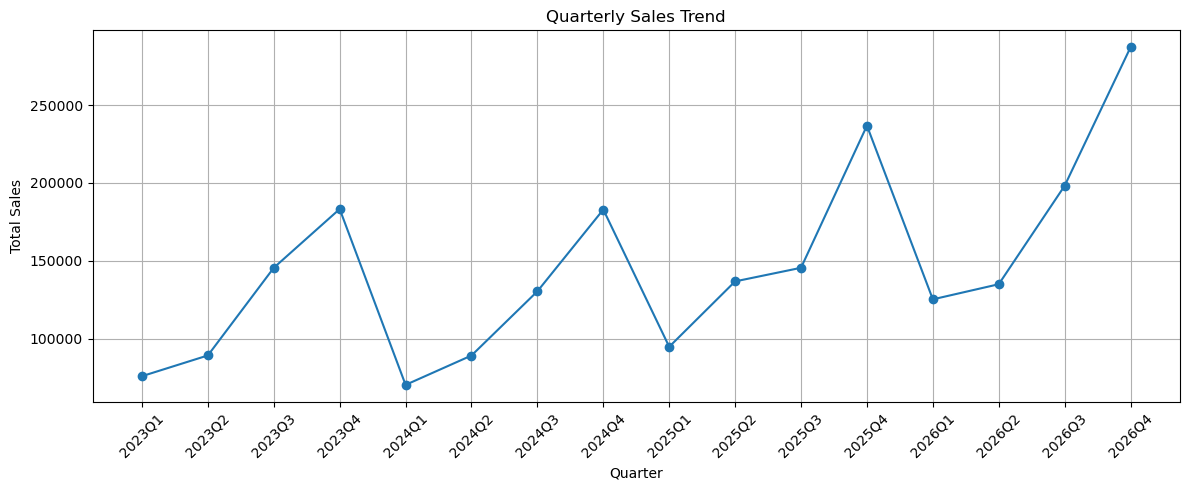

In [15]:
plt.figure(figsize=(12,5))

plt.plot(
    quarterly_analysis['Quarter'].astype(str),
    quarterly_analysis['Total_Sales'],
    marker='o'
)

plt.title('Quarterly Sales Trend')
plt.xlabel('Quarter')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

### Analyze yearly trend

In [16]:
yearly_analysis = df.groupby('Year').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Orders=('Order ID', 'nunique')
).reset_index()

print(yearly_analysis)

   Year  Total_Sales  Total_Profit  Total_Orders
0  2023  494040.2121    51684.2957           995
1  2024  472993.0310    62020.9695          1053
2  2025  613933.5800    82665.2018          1340
3  2026  745567.5312    95926.3476          1723


### Visualize yearly sales

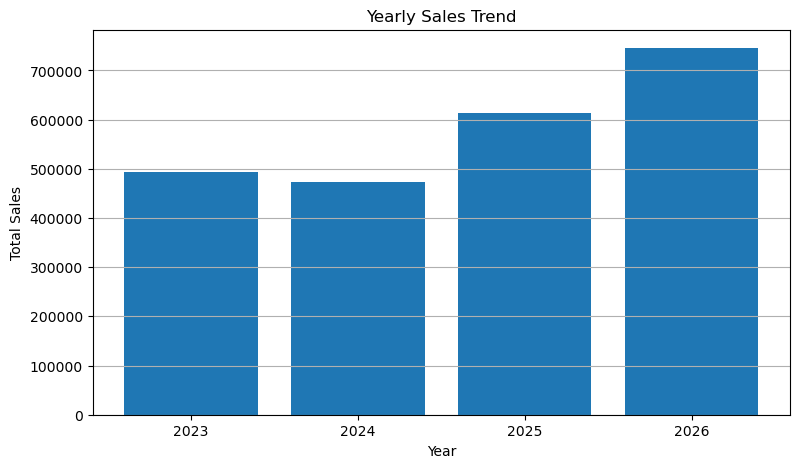

In [17]:
plt.figure(figsize=(9,5))

plt.bar(
    yearly_analysis['Year'].astype(str),
    yearly_analysis['Total_Sales']
)

plt.title('Yearly Sales Trend')
plt.xlabel('Year')
plt.ylabel('Total Sales')
plt.grid(axis='y')
plt.show()

### Compare yearly profit

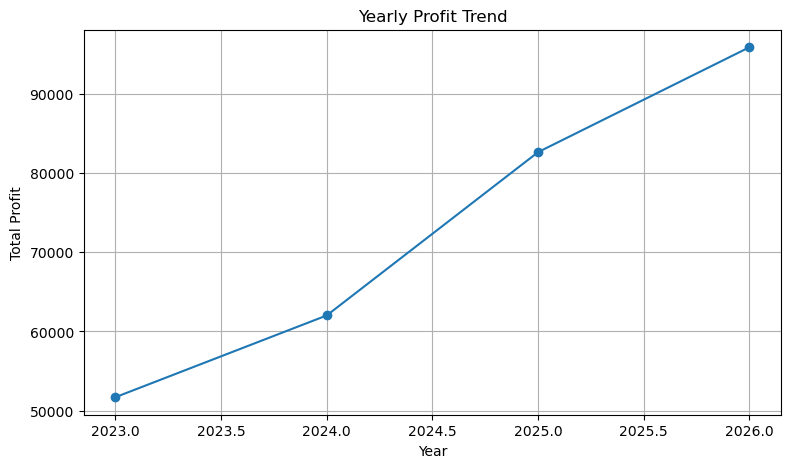

In [18]:
plt.figure(figsize=(9,5))

plt.plot(
    yearly_analysis['Year'],
    yearly_analysis['Total_Profit'],
    marker='o'
)

plt.title('Yearly Profit Trend')
plt.xlabel('Year')
plt.ylabel('Total Profit')
plt.grid()
plt.show()

### Calculate growth percentage

In [19]:
yearly_analysis['Sales_Growth_%'] = (
    yearly_analysis['Total_Sales'].pct_change() * 100
)

print(yearly_analysis)

   Year  Total_Sales  Total_Profit  Total_Orders  Sales_Growth_%
0  2023  494040.2121    51684.2957           995             NaN
1  2024  472993.0310    62020.9695          1053       -4.260216
2  2025  613933.5800    82665.2018          1340       29.797595
3  2026  745567.5312    95926.3476          1723       21.441074
